# 02 · Exploratory analysis: when was it scraped, what's missing, how slow are courts?

The three facts that decide how this data can be modelled, then the patterns in Tamil Nadu.

In [1]:
import sys, json, glob
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from tareekh import plotstyle as ps
ps.apply()
CLEAN, KEYS, FIG = ROOT / "data/clean", ROOT / "data/raw/ddl/keys", ROOT / "reports/figures"
A = json.load(open(ROOT / "reports/analysis.json"))
pd.set_option("display.max_colwidth", 70)

## 1. The scrape leaves a fingerprint

There is no "scraped on" column. Decisions per month (all India, every filing year) run steadily, then collapse: that's when the data was collected. A case without a decision is only known to be pending *up to that date*.

2018 median month: 1,011,514 decisions; March 2019: 171,585


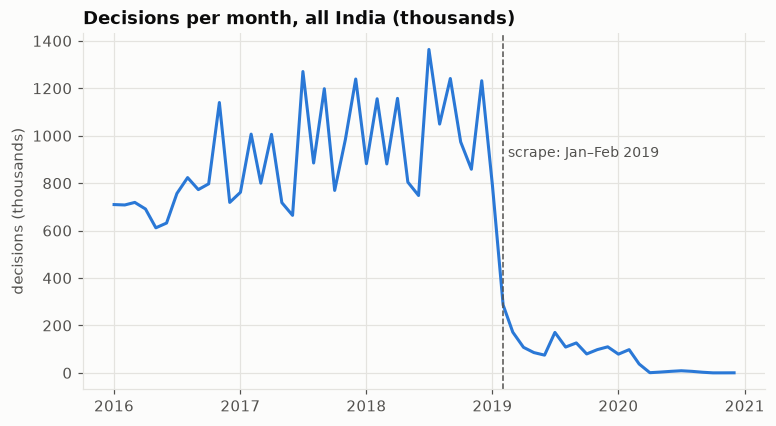

In [2]:
m = pd.Series(A["national"]["monthly_decisions"])
m.index = pd.PeriodIndex(m.index, freq="M").to_timestamp()
fig, ax = plt.subplots()
ax.plot(m.index, m.values / 1e3, color=ps.SERIES[0])
peak = m.loc["2018"].median()
ax.axvline(pd.Timestamp("2019-02-01"), color=ps.INK_2, lw=1, ls="--")
ax.annotate("scrape: Jan–Feb 2019", (pd.Timestamp("2019-02-15"), peak / 1e3 * 0.9), color=ps.INK_2, fontsize=9)
ax.set_title("Decisions per month, all India (thousands)")
ax.set_ylabel("decisions (thousands)")
ps.save(fig, "eda_scrape_cliff", FIG)
print(f"2018 median month: {peak:,.0f} decisions; March 2019: {m.loc['2019-03'].iloc[0]:,.0f}")

## 2. Early years are incomplete

The *same* courts, present from 2010, record far more cases in later years, and same-day disposals appear only later. Cases that ended quickly before a court went digital were mostly never entered, so early cohorts look much slower than they were. **Models use 2015–2017 filings only.**

x3.6 from 2010 to 2018 in the same courts


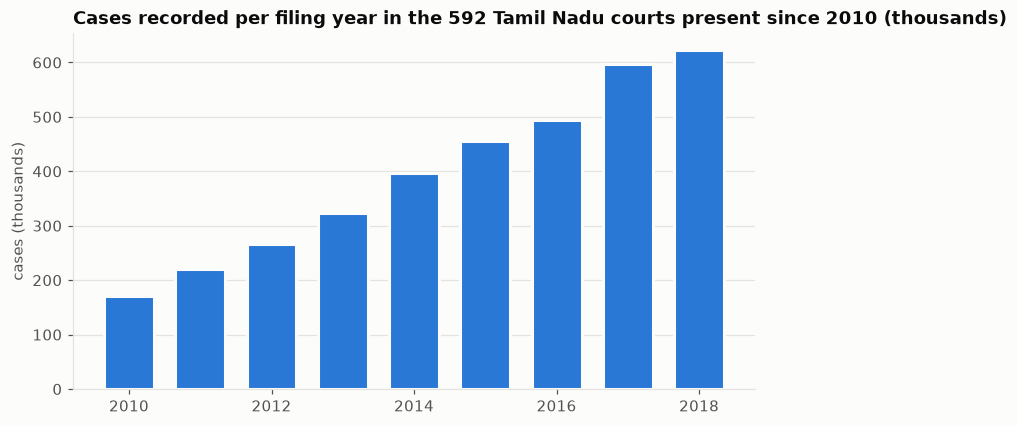

In [3]:
s = A["tamil_nadu"]["survivorship"]
years = sorted(int(y) for y in s["cases_in_those_courts"])
cases = [s["cases_in_those_courts"][str(y)] if str(y) in s["cases_in_those_courts"] else s["cases_in_those_courts"][y] for y in years]
fig, ax = plt.subplots()
ax.bar(years, np.array(cases) / 1e3, color=ps.SERIES[0], width=0.7, edgecolor=ps.SURFACE, linewidth=2)
ax.set_title(f"Cases recorded per filing year in the {s['courts_present_2010']} Tamil Nadu courts present since 2010 (thousands)")
ax.set_ylabel("cases (thousands)"); ax.grid(axis="x", visible=False)
ps.save(fig, "eda_survivorship", FIG)
print(f"x{cases[-1] / cases[0]:.1f} from {years[0]} to {years[-1]} in the same courts")

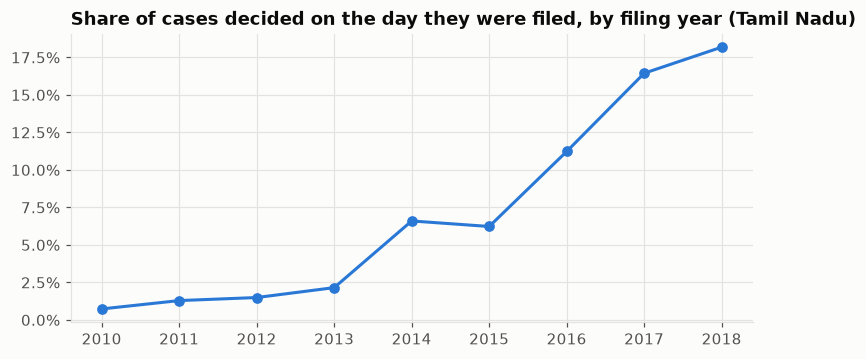

In [4]:
same_day = pd.Series(s["same_day_share"]).rename(int)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(same_day.index, same_day.values, marker="o", color=ps.SERIES[0])
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title("Share of cases decided on the day they were filed, by filing year (Tamil Nadu)")
ps.save(fig, "eda_same_day", FIG)

## 3. "Median days to decision" is a trap

Among *decided* cases the median collapses to almost nothing for recent years, only because recent slow cases haven't finished yet. Kaplan–Meier counts every case for as long as it was watched. Its median falls too: part of that is courts genuinely getting faster, part is the early-year survivorship from section 2 (the 2010 cohort is missing its quick cases), which is why the model doesn't use those years.

,median among decided,Kaplan-Meier median
filing_year,,
2010,1366.0,1675.0
2011,938.0,1224.0
2012,768.0,1051.0
2013,572.0,932.0
2014,357.0,771.0
2015,296.0,763.0
2016,126.0,590.0
2017,17.0,445.0
2018,2.0,387.0


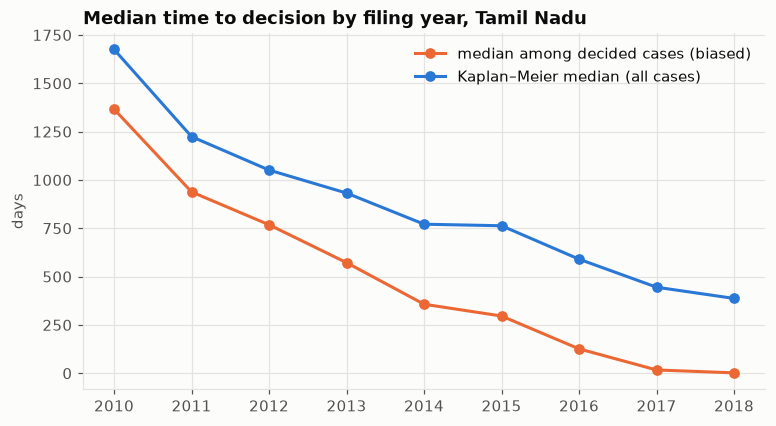

In [5]:
from tareekh.survival import kaplan_meier, median_days
lab = pd.read_parquet(CLEAN / "10/labelled.parquet")
ok = lab[lab.unusable == ""]
rows = []
for y, part in ok.groupby("filing_year"):
    rows.append({"filing_year": y, "median among decided": part.loc[part.ended, "observed_days"].median(),
                 "Kaplan-Meier median": median_days(kaplan_meier(part.observed_days, part.ended))})
med = pd.DataFrame(rows).set_index("filing_year")
fig, ax = plt.subplots()
ax.plot(med.index, med["median among decided"], marker="o", color=ps.SERIES[1], label="median among decided cases (biased)")
ax.plot(med.index, med["Kaplan-Meier median"], marker="o", color=ps.SERIES[0], label="Kaplan–Meier median (all cases)")
ax.legend(loc="upper right"); ax.set_ylabel("days"); ax.set_title("Median time to decision by filing year, Tamil Nadu")
ps.save(fig, "eda_median_trap", FIG)
med.round(0)

## 4. Pending share varies hugely by state

Share of 2010 filings still open at each state's scrape cutoff. Part real backlog, part cases never updated in the system. States without a clear scrape date are left out.

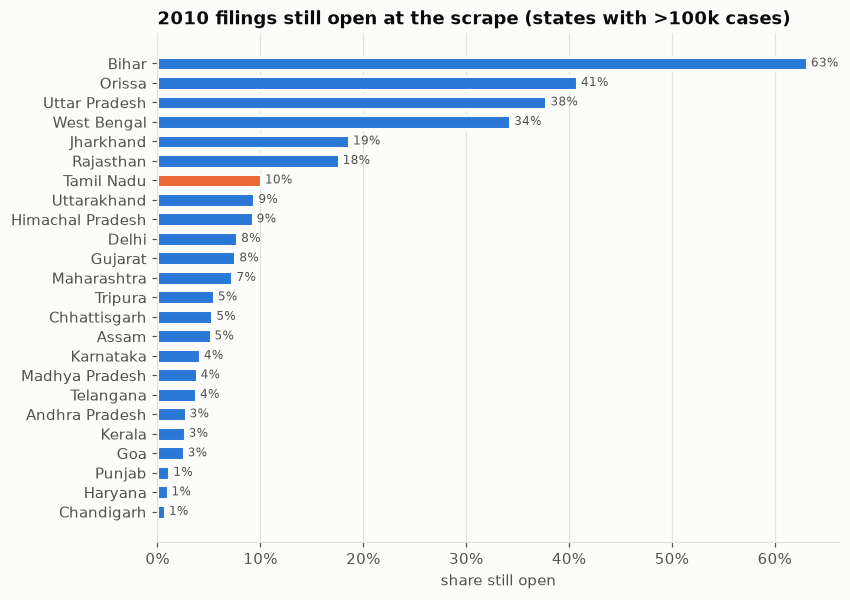

In [6]:
st = pd.DataFrame(A["national"]["states"]).dropna(subset=["pending_2010_filings"])
st = st[st.cases > 100_000]
fig, ax = plt.subplots(figsize=(8, 6))
ps.hbar(ax, list(st.state), list(st.pending_2010_filings), highlight={"Tamil Nadu"})
ax.set_title("2010 filings still open at the scrape (states with >100k cases)")
ax.set_xlabel("share still open"); ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ps.save(fig, "eda_pending_by_state", FIG)

## 5. Tamil Nadu: what kind of case, and which court, decide the pace

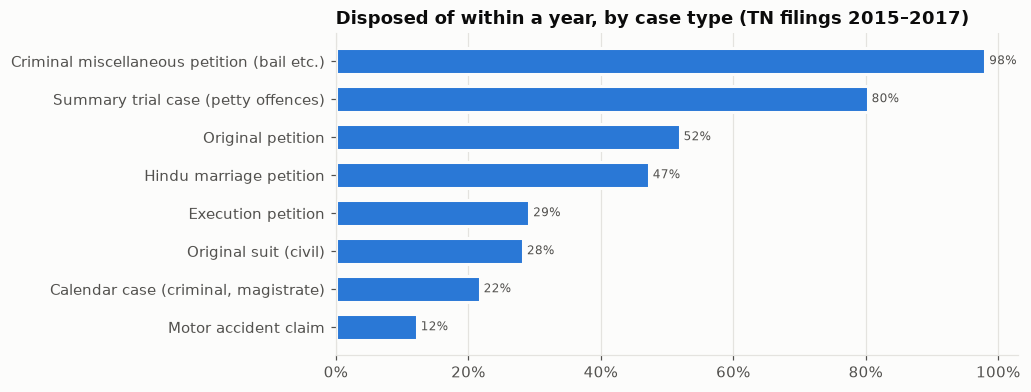

In [7]:
t = pd.DataFrame(A["tamil_nadu"]["within_1y_by_type"])
names = {k: v["label"] for k, v in A["tamil_nadu"]["still_open_curves"].items()}
fig, ax = plt.subplots(figsize=(8, 3.8))
ps.hbar(ax, [names.get(x, x) for x in t["type"]], list(t["mean"]))
ax.set_title("Disposed of within a year, by case type (TN filings 2015–2017)")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ps.save(fig, "eda_within_1y_by_type", FIG)

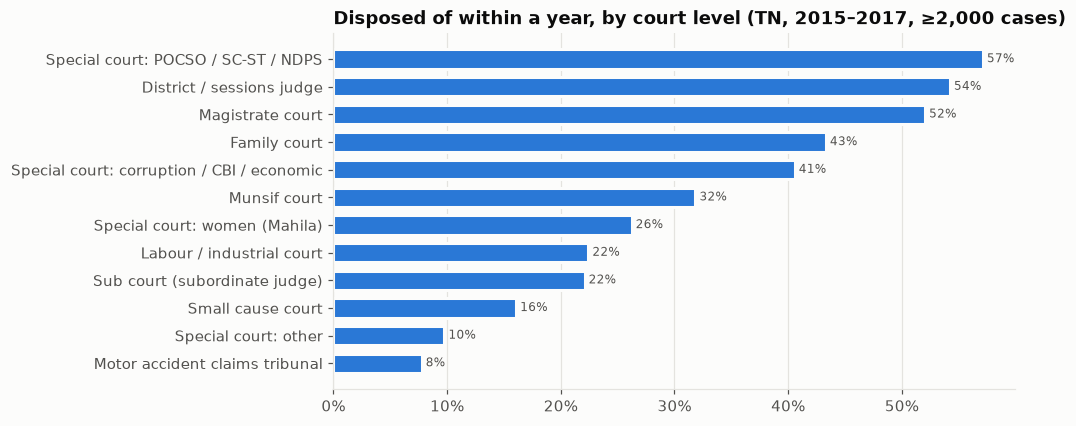

In [8]:
c = pd.DataFrame(A["tamil_nadu"]["within_1y_by_court_level"])
c = c[c["size"] >= 2000]
fig, ax = plt.subplots(figsize=(8, 4.2))
ps.hbar(ax, list(c.court_level), list(c["mean"]))
ax.set_title("Disposed of within a year, by court level (TN, 2015–2017, ≥2,000 cases)")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ps.save(fig, "eda_within_1y_by_court", FIG)

fastest Theni 74%, slowest Perambalur 19%


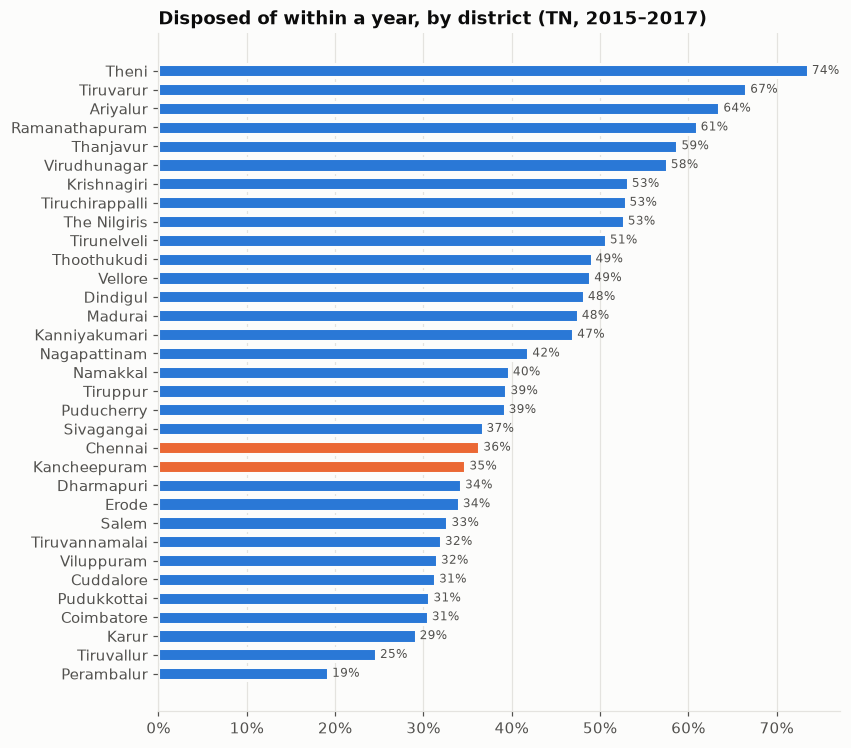

In [9]:
d = pd.DataFrame(A["tamil_nadu"]["within_1y_by_district"])
fig, ax = plt.subplots(figsize=(8, 8))
ps.hbar(ax, list(d.district), list(d["mean"]), highlight={"Chennai", "Kancheepuram"})
ax.set_title("Disposed of within a year, by district (TN, 2015–2017)")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ps.save(fig, "eda_within_1y_by_district", FIG)
print(f"fastest {d.iloc[-1].district} {d.iloc[-1]['mean']:.0%}, slowest {d.iloc[0].district} {d.iloc[0]['mean']:.0%}")

## Takeaways

- **Cutoff:** the data was scraped in Jan–Feb 2019; labels must respect that date, per district.
- **Survivorship:** the early years are missing their quick cases; only 2015–2017 filings are used
  for modelling.
- **Bias trap:** "median among decided cases" is meaningless here; Kaplan–Meier is the honest view.
- **Pace:** case type is by far the biggest factor (petty summary trials and criminal petitions end
  within weeks, accident claims and appeals take years); the court level and district matter less.